In [1]:
import awswrangler as wr

import mlflow

# Estas variables ya vienen seteadas por docker-compose en el contenedor de Jupyter
# (ver servicio `jupyter` en docker-compose.yaml). Se dejan acá también por las dudas
# de que alguien corra esta celda en otro contexto.
%env AWS_ACCESS_KEY_ID=minio
%env AWS_SECRET_ACCESS_KEY=minio123
%env MLFLOW_S3_ENDPOINT_URL=http://s3:9000
%env AWS_ENDPOINT_URL_S3=http://s3:9000


env: AWS_ACCESS_KEY_ID=minio
env: AWS_SECRET_ACCESS_KEY=minio123
env: MLFLOW_S3_ENDPOINT_URL=http://s3:9000
env: AWS_ENDPOINT_URL_S3=http://s3:9000


/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Búsqueda de mejor modelo e hiperparámetros — Familia olfativa de perfumes

Dado el dataset de perfumes (Parfumo), que ya pasó por el DAG de ETL `process_perfume_data` y se
encuentra en nuestro bucket S3 (`s3://data/final/...`), vamos a buscar cuál es el mejor modelo y
qué hiperparámetros usar para predecir la **familia olfativa dominante** de un perfume a partir de
su composición de notas.

La búsqueda de hiperparámetros se hace con **Optuna** (búsqueda Bayesiana) y el tracking con
**MLflow**, igual que en el ejemplo de Heart Disease de la cátedra. La diferencia principal es el
problema en sí: acá es clasificación **multiclase** (20 familias olfativas) con fuerte desbalance
de clases, así que la métrica que se optimiza es `f1_macro` en vez de accuracy o f1 binario (ver
`notebook_example/optuna_aux.py` para el detalle del porqué).

Este notebook retoma directamente el TP de Aprendizaje de Máquina I *"Clasificación de familia
olfativa en perfumes a partir de su composición de notas"* (nota 10/10): los 5 algoritmos
comparados (KNN, Árbol de decisión, Random Forest, Gradient Boosting, SVM) son los mismos, pero acá
la búsqueda de hiperparámetros está automatizada con Optuna y trackeada en MLflow en vez de hacerse
con GridSearchCV/manualmente en un notebook local, que es justamente lo que pide productivizar el
TP de MLOps.

> **Nota de tiempos:** con ~16.800 filas x 256 features, esto es bastante más pesado que el
> ejemplo de Heart Disease (dataset chico). Por eso acá se usa `cv=3` (no 5) y un número de
> trials moderado (`n_trials=30`, no 250): aun así, los trials de SVM con kernel RBF pueden tardar
> varios minutos cada uno. Si estás corriendo esto para la entrega parcial del domingo y no da el
> tiempo, bajá `n_trials` a un número más chico (por ejemplo 10) — igual vas a tener resultados en
> MLflow para mostrar avance, que es lo que pide la consigna de esa entrega.


In [2]:
# "mlflow" es el nombre del servicio en docker-compose.yaml (todo corre en la
# misma red de Docker, por eso no usamos localhost ni un puerto publicado al host).
mlflow_server = "http://mlflow:5000"

mlflow.set_tracking_uri(mlflow_server)


In [3]:
# Cargamos los datos que arma el DAG de ETL (process_perfume_data). Nada de test acá,
# ninguna decision de modelado se apoya en el set de test.
X_train = wr.s3.read_csv("s3://data/final/train/perfume_X_train.csv")
y_train = wr.s3.read_csv("s3://data/final/train/perfume_y_train.csv")

X_test = wr.s3.read_csv("s3://data/final/test/perfume_X_test.csv")
y_test = wr.s3.read_csv("s3://data/final/test/perfume_y_test.csv")

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Clases:", sorted(y_train['dominant_accord'].unique()))


X_train: (16825, 256)  X_test: (4207, 256)
Clases: ['Animal', 'Aquatic', 'Chypre', 'Citrus', 'Creamy', 'Earthy', 'Floral', 'Fresh', 'Fruity', 'Gourmand', 'Green', 'Leathery', 'Oriental', 'Powdery', 'Resinous', 'Smoky', 'Spicy', 'Sweet', 'Synthetic', 'Woody']


## Distribución de clases en train

Antes de modelar, un recordatorio visual del desbalance (documentado en detalle en el TP de
AMq1, sección 2.5): esto es lo que justifica usar `f1_macro` como métrica principal más abajo.


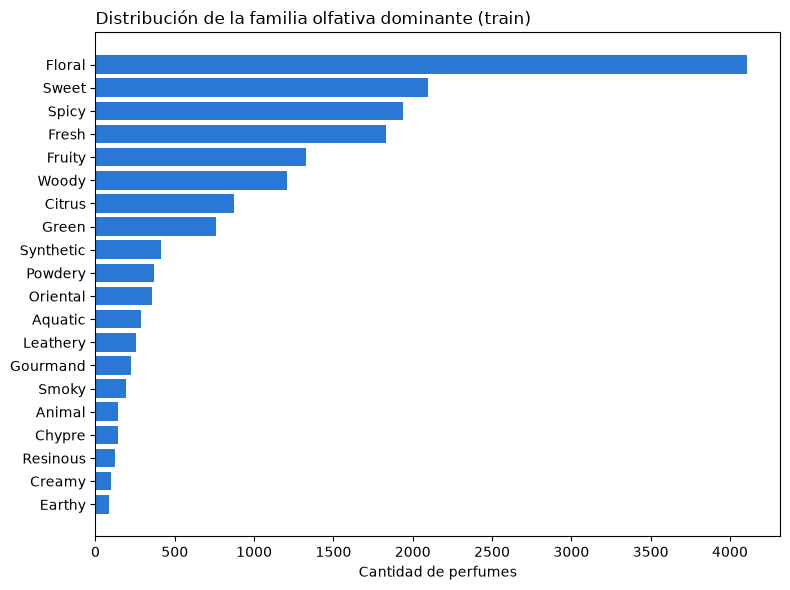

In [4]:
import matplotlib.pyplot as plt

vc = y_train['dominant_accord'].value_counts().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(vc.index, vc.values, color="#2a78d6")
ax.set_title("Distribución de la familia olfativa dominante (train)", loc="left")
ax.set_xlabel("Cantidad de perfumes")
plt.tight_layout()
plt.show()


## Arrancamos a experimentar

In [5]:
import datetime
import optuna

from mlflow.models import infer_signature
from mlflow_aux import get_or_create_experiment

from optuna_aux import champion_callback, objective

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score

# Optuna es un poco verboso, dejamos que solo nos muestre logs de errores
optuna.logging.set_verbosity(optuna.logging.ERROR)


Antes de poder realizar experimentos, creamos el experimento en MLflow (o recuperamos su ID si ya
existe), y armamos el nombre del run padre bajo el que se van a anidar todos los trials.


In [6]:
experiment_id = get_or_create_experiment("Perfume Olfactory Family")
print(experiment_id)

run_name_parent = "best_hyperparam_" + datetime.datetime.today().strftime('%Y/%m/%d-%H:%M:%S"')


1


Ejecutamos la optimización. `n_trials=30` es un punto de partida razonable para una laptop; subilo
si tenés tiempo/cómputo de sobra, bajalo si estás corriendo esto contrarreloj para la entrega
parcial.


In [7]:
N_TRIALS = 30

def build_model_from_params(params):
    """Reconstruye el estimador de sklearn a partir de los mejores hiperparámetros que
    encontró Optuna (mismo mapeo classifier_name -> constructor que usa `objective` en
    optuna_aux.py)."""
    name = params["classifier"]
    if name == "KNN":
        return KNeighborsClassifier(n_neighbors=params["knn_n_neighbors"], weights=params["knn_weights"])
    if name == "DecisionTree":
        return DecisionTreeClassifier(max_depth=params["tree_max_depth"],
                                       min_samples_leaf=params["tree_min_samples_leaf"])
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=params["rf_n_estimators"],
                                       max_depth=params["rf_max_depth"],
                                       min_samples_leaf=params["rf_min_samples_leaf"],
                                       n_jobs=-1)
    if name == "GradientBoosting":
        return HistGradientBoostingClassifier(learning_rate=params["gb_learning_rate"],
                                               max_depth=params["gb_max_depth"],
                                               l2_regularization=params["gb_l2_regularization"],
                                               max_iter=300, early_stopping=True)
    # SVC_rbf
    return SVC(C=params["svc_c"], kernel="rbf", gamma="scale")


with mlflow.start_run(experiment_id=experiment_id, run_name=run_name_parent, nested=True):
    study = optuna.create_study(direction="maximize")

    study.optimize(lambda trial: objective(trial, X_train, y_train, experiment_id),
                    n_trials=N_TRIALS, callbacks=[champion_callback])

    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_train_f1_macro", study.best_value)

    mlflow.set_tags(tags={
        "project": "Perfume Astral - Familia Olfativa",
        "optimizer_engine": "optuna",
        "model_family": "sklearn",
        "feature_set_version": 1,
    })

    model = build_model_from_params(study.best_params)
    model = model.fit(X_train, y_train.to_numpy().ravel())

    y_pred_test = model.predict(X_test)
    test_f1_macro = f1_score(y_test.to_numpy().ravel(), y_pred_test, average="macro")
    mlflow.log_metric("test_f1_macro", test_f1_macro)
    print("Mejor modelo:", study.best_params)
    print("f1_macro en test:", test_f1_macro)

    artifact_path = "model"
    signature = infer_signature(X_train, model.predict(X_train))

    mlflow.sklearn.log_model(
        sk_model=model,
        artifact_path=artifact_path,
        signature=signature,
        serialization_format="cloudpickle",
        registered_model_name="perfume_accord_model_dev",
        metadata={"model_data_version": 1}
    )

    model_uri = mlflow.get_artifact_uri(artifact_path)


2026/09/27 13:58:15 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/09/27 13:58:15 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

🏃 View run Trial: 0 at: http://mlflow:5000/#/experiments/1/runs/541d454f12a34f52b2248d7a9b020b96
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Initial trial 0 achieved value: 0.06364523992686379
🏃 View run Trial: 1 at: http://mlflow:5000/#/experiments/1/runs/e3c4302341d2410d9fd802b7b18d216d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run Trial: 2 at: http://mlflow:5000/#/experiments/1/runs/47af796cb9d243eb83aec2ba734bc84e
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Trial 2 achieved value: 0.10413090606403513 with  38.8796% improvement
🏃 View run Trial: 3 at: http://mlflow:5000/#/experiments/1/runs/c9df2c2603bf4f3185d3e2683dbc1e7a
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run Trial: 4 at: http://mlflow:5000/#/experiments/1/runs/7c4ac81e2b9d482a8159ad5bedef93f3
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run Trial: 5 at: http://mlflow:5000/#/experiments/1/runs/39772e290b4945c4a1542b04a753ecad
🧪 View exp

2026/09/27 14:11:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/27 14:11:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Successfully registered model 'perfume_accord_model_dev'.
2026/09/27 14:11:51 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: perfume_accord_model_dev, version 1


🏃 View run best_hyperparam_2026/09/27-13:58:15" at: http://mlflow:5000/#/experiments/1/runs/a80394cb002247f49e2f3e7e17cdd818
🧪 View experiment at: http://mlflow:5000/#/experiments/1


Created version '1' of model 'perfume_accord_model_dev'.


In [11]:
# Vuelve a guardar el modelo ya entrenado, pero con la forma correcta para MLflow 3.x
# (tomando la URL directo de lo que devuelve log_model, no reconstruida a mano).
with mlflow.start_run(experiment_id=experiment_id, run_name="fix_model_uri_reload") as run:
    model_info = mlflow.sklearn.log_model(
        sk_model=model,
        name="model",
        signature=signature,
        serialization_format="cloudpickle",
    )
    model_uri = model_info.model_uri
    run_id = run.info.run_id

print(model_uri)

2026/09/27 14:18:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run fix_model_uri_reload at: http://mlflow:5000/#/experiments/1/runs/9b98fefe57044c6daec3a8b8a362f1c8
🧪 View experiment at: http://mlflow:5000/#/experiments/1
models:/m-01f8d98106624813835fa41a127b1c23


## Testeando el modelo

Una vez entrenado el modelo, lo levantamos y lo testeamos de forma agnóstica a dónde está guardado
(desde el artifact store de MLflow, no desde una variable en memoria).


In [12]:
loaded = mlflow.sklearn.load_model(model_uri)


In [13]:
# Sanity check: predecimos sobre las primeras 5 filas del set de test y comparamos con el
# valor real.
preds = loaded.predict(X_test.iloc[:5])
for pred, real in zip(preds, y_test['dominant_accord'].iloc[:5]):
    print(f"Predicho: {pred:12s}  Real: {real}")


Predicho: Sweet         Real: Earthy
Predicho: Fruity        Real: Floral
Predicho: Floral        Real: Spicy
Predicho: Chypre        Real: Chypre
Predicho: Floral        Real: Floral


## Registramos el modelo

Lo registramos en MLflow como modelo productivo (`perfume_accord_model_prod`), con el alias
`champion`, que es lo que va a levantar `dockerfiles/fastapi/app.py` para servir predicciones, y lo
que compara `airflow/dags/retrain_the_model.py` contra el `challenger` en cada reentrenamiento.


In [14]:
from mlflow import MlflowClient

client = MlflowClient()
name = "perfume_accord_model_prod"
desc = "Clasifica la familia olfativa dominante de un perfume a partir de su composición de notas (top/middle/base) y metadata básica."

# Si ya existe (por ejemplo, corriste esta celda antes), no pasa nada, seguimos.
try:
    client.create_registered_model(name=name, description=desc)
except Exception as e:
    if "RESOURCE_ALREADY_EXISTS" not in str(e):
        raise

tags = model.get_params()
tags["model"] = type(model).__name__
tags["f1-macro-test"] = test_f1_macro

result = client.create_model_version(
    name=name,
    source=model_uri,
    run_id=run_id,
    tags=tags
)

client.set_registered_model_alias(name, "champion", result.version)
print(f"Modelo registrado como versión {result.version}, alias 'champion'.")

2026/09/27 14:20:32 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: perfume_accord_model_prod, version 2


Modelo registrado como versión 2, alias 'champion'.
